In [1]:
# !pip install category-encoders

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay , classification_report , accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from category_encoders import OrdinalEncoder
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

C:\Users\tanni\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
df = pd.read_csv('loan_data.csv')
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
1,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
2,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
3,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
4,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y


In [4]:
df.drop(columns=['Loan_ID'], errors='ignore', inplace=True)
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
1,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
2,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
3,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
4,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y


In [5]:
print(f"The shape of the Data Frame is: {df.shape}")

The shape of the Data Frame is: (381, 12)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             376 non-null    str    
 1   Married            381 non-null    str    
 2   Dependents         373 non-null    str    
 3   Education          381 non-null    str    
 4   Self_Employed      360 non-null    str    
 5   ApplicantIncome    381 non-null    int64  
 6   CoapplicantIncome  381 non-null    float64
 7   LoanAmount         381 non-null    float64
 8   Loan_Amount_Term   370 non-null    float64
 9   Credit_History     351 non-null    float64
 10  Property_Area      381 non-null    str    
 11  Loan_Status        381 non-null    str    
dtypes: float64(4), int64(1), str(7)
memory usage: 45.9 KB


In [7]:
#Statistical informations
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,381.000000,381.000000,381.000000,370.000000,351.000000
mean,3579.845144,1277.275381,104.986877,340.864865,0.837607
std,1419.813818,2340.818114,28.358464,68.549257,0.369338
min,150.000000,0.000000,9.000000,12.000000,0.000000
25%,2600.000000,0.000000,90.000000,360.000000,1.000000
50%,3333.000000,983.000000,110.000000,360.000000,1.000000
75%,4288.000000,2016.000000,127.000000,360.000000,1.000000
max,9703.000000,33837.000000,150.000000,480.000000,1.000000


In [8]:
#Show duplicated rows
df.duplicated().sum()

np.int64(0)

In [9]:
#Show NaN values
df.isna().sum()

Gender                5
Married               0
Dependents            8
Education             0
Self_Employed        21
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term     11
Credit_History       30
Property_Area         0
Loan_Status           0
dtype: int64

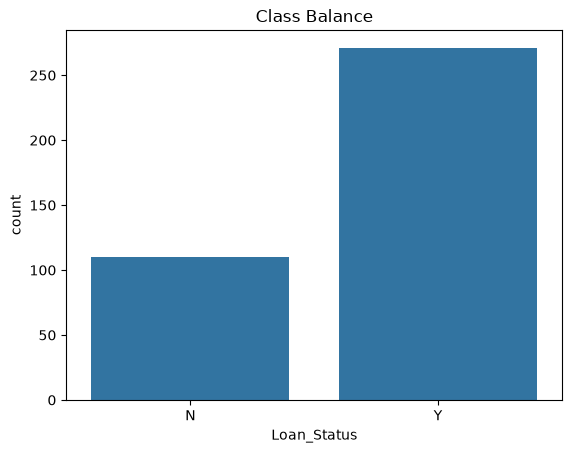

In [10]:
sns.countplot(x=df['Loan_Status'])
plt.title('Class Balance');

In [11]:
df = df.replace(to_replace= '3+',value=4)
df['Dependents'].value_counts()

Dependents
0    234
2     59
1     52
4     28
Name: count, dtype: int64

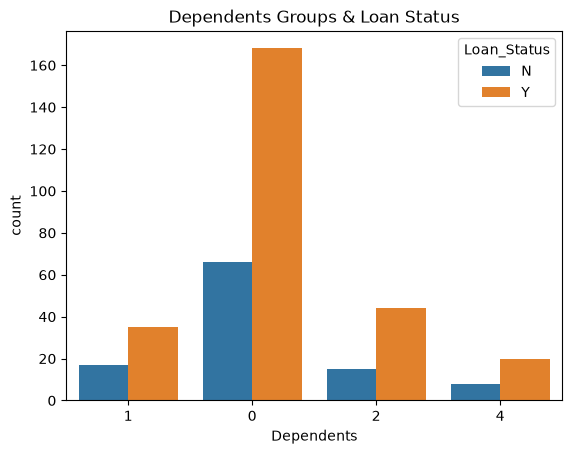

In [12]:
sns.countplot(x= df['Dependents'] , hue= df['Loan_Status'])
plt.title('Dependents Groups & Loan Status');

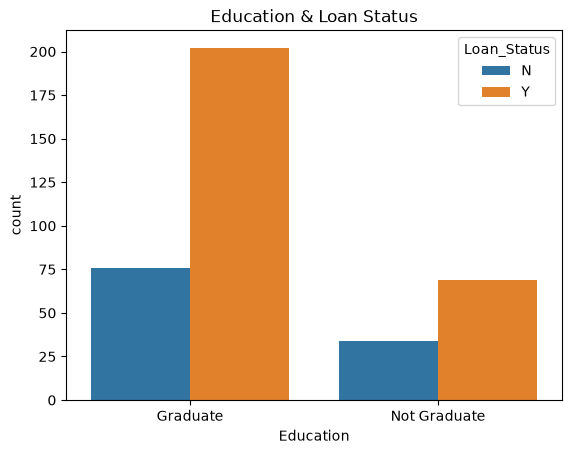

In [13]:
sns.countplot(x= df['Education'] , hue= df['Loan_Status'])
plt.title('Education & Loan Status');

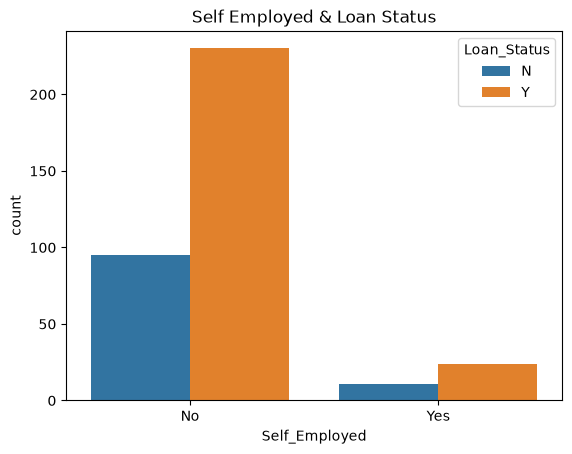

In [14]:
sns.countplot(x= df['Self_Employed'] , hue= df['Loan_Status'])
plt.title('Self Employed & Loan Status');

In [15]:
target= 'Loan_Status'
X= df.drop(columns=[target])
y= df[target]
print(f'X Shape {X.shape}')
print(f'y Shape {y.shape}')

X Shape (381, 11)
y Shape (381,)


In [16]:
X_test , X_train , y_test , y_train = train_test_split(X,y,test_size= 0.2 , random_state= 42)

In [17]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (77, 11)
y_train shape: (77,)
X_test shape: (304, 11)
y_test shape: (304,)


In [18]:
acc_baseline = df['Loan_Status'].value_counts(normalize= True).max()
print(f'Baseline Accuracy is {acc_baseline}')

Baseline Accuracy is 0.7112860892388452


In [19]:
def train(model , model_name):
    model.fit(X_train, y_train)
    print(f'training accuracy of {model_name} is: {model.score(X_test , y_test)}')
    print(f'testing accuracy of {model_name} is: {model.score(X_test , y_test)}')
def conf_matrix(model):
    ConfusionMatrixDisplay.from_estimator(
        svm_model,
        X_test,
        y_test
    )
def class_report(model):
    print(classification_report(y_test , model.predict(X_test)))

In [20]:
#Build Model
svm_model= make_pipeline(
    OrdinalEncoder(),
    SimpleImputer(),
    MinMaxScaler(),
    SVC(kernel='linear')
)

In [21]:
train(svm_model , "SVC" )

training accuracy of SVC is: 0.8519736842105263
testing accuracy of SVC is: 0.8519736842105263


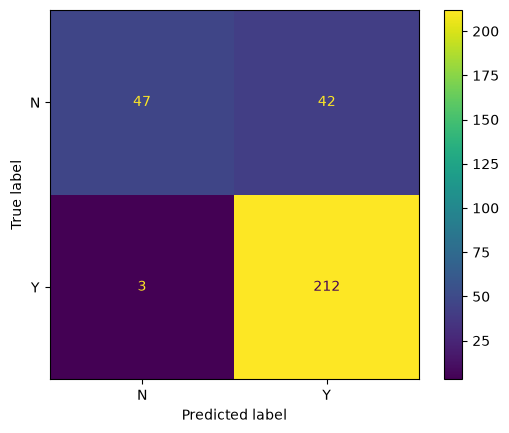

In [22]:
conf_matrix(svm_model)

In [23]:
class_report(svm_model)

              precision    recall  f1-score   support

           N       0.94      0.53      0.68        89
           Y       0.83      0.99      0.90       215

    accuracy                           0.85       304
   macro avg       0.89      0.76      0.79       304
weighted avg       0.87      0.85      0.84       304



In [24]:
#Build Model
Logistic_model= make_pipeline(
    OrdinalEncoder(),
    SimpleImputer(),
    MinMaxScaler(),
    LogisticRegression()
)

In [25]:
train(Logistic_model , "LogisticRegression" )

training accuracy of LogisticRegression is: 0.8157894736842105
testing accuracy of LogisticRegression is: 0.8157894736842105


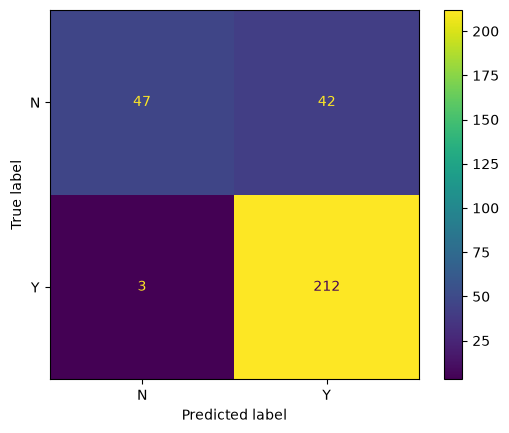

In [26]:
conf_matrix(Logistic_model)

In [27]:
class_report(Logistic_model)

              precision    recall  f1-score   support

           N       0.80      0.49      0.61        89
           Y       0.82      0.95      0.88       215

    accuracy                           0.82       304
   macro avg       0.81      0.72      0.75       304
weighted avg       0.81      0.82      0.80       304



In [28]:
features = X_test.columns
importances= Logistic_model.named_steps['logisticregression'].coef_[0]

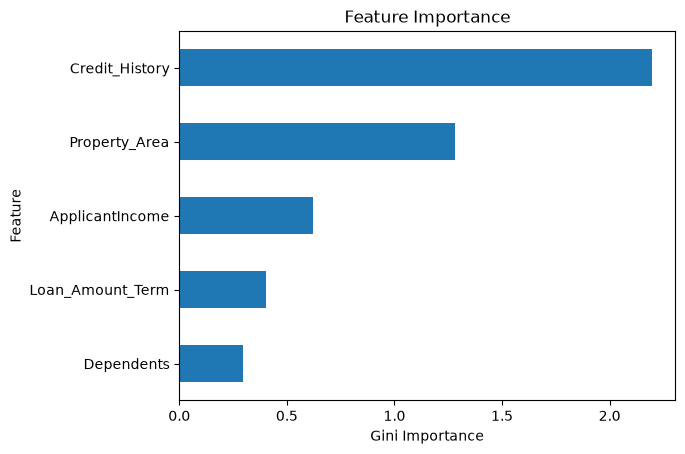

In [29]:
feat_imp = pd.Series(importances , index=features).sort_values()
feat_imp.tail().plot(kind= 'barh')
plt.xlabel("Gini Importance")
plt.ylabel("Feature")
plt.title("Feature Importance");